check_event  : Everything looks fine...
[2457205.21, 0.309, 10.7821, 1.3, 0.001, 1.9, np.float64(10000.0), np.float64(12000.0)]


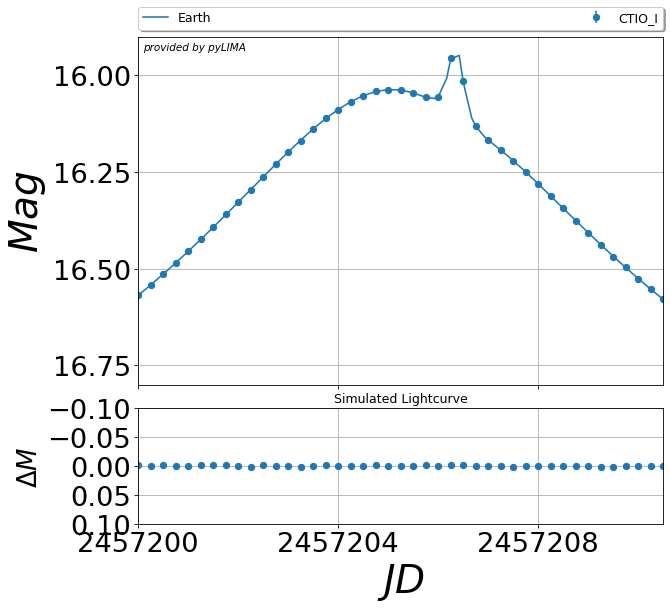

In [1]:
from pyLIMA import event
from pyLIMA.simulations import simulator
from pyLIMA.fits import TRF_fit
from pyLIMA.models import PSBL_model
from pyLIMA.outputs import pyLIMA_plots
import numpy as np
import matplotlib.pyplot as plt

# Create simulated Microlensing event
event_3 = event.Event(ra=270, dec=0)
event_3.name = 'My simulated event'

CTIO_I = simulator.simulate_a_telescope(name='CTIO_I', time_start=2457190, time_end=2457220, sampling=6, 
                                        location='Earth', camera_filter='I',
                                        uniform_sampling=True, astrometry=False)
# LCO_SAAO = simulator.simulate_a_telescope(name='LCO_SAAO', time_start=2457205, time_end=2457208, sampling=1, 
#                                         location='Earth', camera_filter='I',
#                                         uniform_sampling=True, astrometry=False)

event_3.telescopes.append(CTIO_I)
# event_3.telescopes.append(LCO_SAAO)
event_3.check_event()

psbl_sim = PSBL_model.PSBLmodel(event_3)
psbl_sim_params = simulator.simulate_microlensing_model_parameters(psbl_sim)

### Set the parameters to some reasonable values.
psbl_sim_params[0] = 2457205.21 # t0
psbl_sim_params[1:3] = [0.309, 10.7821] # u0, tE
psbl_sim_params[3:6] = [1.3, 0.001, 1.9] # s, q, alpha

### Set the source and blend fluxes of all telescopes to the same values for plotting purposes.
n_tel = len(event_3.telescopes)
psbl_sim_params[-n_tel*2::2] = 10000. * np.ones(n_tel) # source fluxes
psbl_sim_params[-n_tel*2+1::2] = 12000. * np.ones(n_tel) # total fluxes
print(psbl_sim_params)

### Transform the parameters into a pyLIMA class object.
pyLIMA_parameters_1 = psbl_sim.compute_pyLIMA_parameters(psbl_sim_params)

### Inject everthing into the simulator to produce a light curve.
simulator.simulate_lightcurve(psbl_sim, pyLIMA_parameters_1)

pyLIMA_plots.plot_lightcurves(psbl_sim, psbl_sim_params)
plt.title('Simulated Lightcurve')
plt.gcf().axes[0].set_xlim(2457200.0, 2457210.5)
plt.gcf().axes[0].set_ylim(16.8, 15.9)
plt.show()

Selecting CTIO_I to estimate u0, tE and fs
initial_guess  : Initial parameters guess SUCCESS
Using guess:  [2457205.25, 0.4730922896672884, 5.5, 18573.348755381146, 14328.627076687386]
Trust Region Reflective fit SUCCESS
best model:
OrderedDict([('t0', np.float64(2457205.189873185)),
             ('u0', np.float64(0.31873576232245426)),
             ('tE', np.float64(10.614547849984799)),
             ('fsource_CTIO_I', np.float64(10258.764957781448)),
             ('ftotal_CTIO_I', np.float64(12025.45228311282)),
             ('soft_l1', np.float64(748.439782881145))])


/home/jakob/projects/pyLIMA-docs-revisit/my_project/planet_anomaly/planet_anomaly.py:89: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


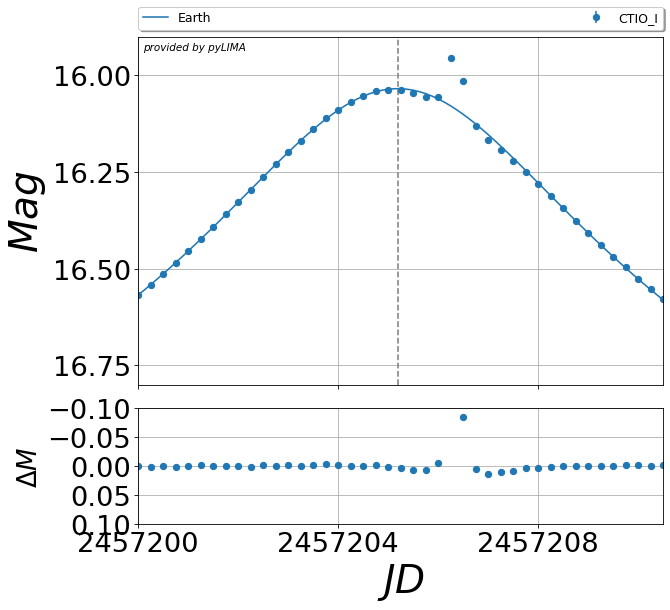

In [2]:
from planet_anomaly import PlanetAnomalyDetector, PlanetAnomalyMap, PlanetAnomalyPlot, PlanetAnomalySampler

anomaly_detector = PlanetAnomalyDetector(event=event_3, 
                                window_limits=((2457200.0, 2457210.5),(16.8, 15.9)))

anomaly_detector.run_pspl_fit()
fig_pspl = anomaly_detector.plot_pspl_model(show=True)


Planet Anomaly Map done.


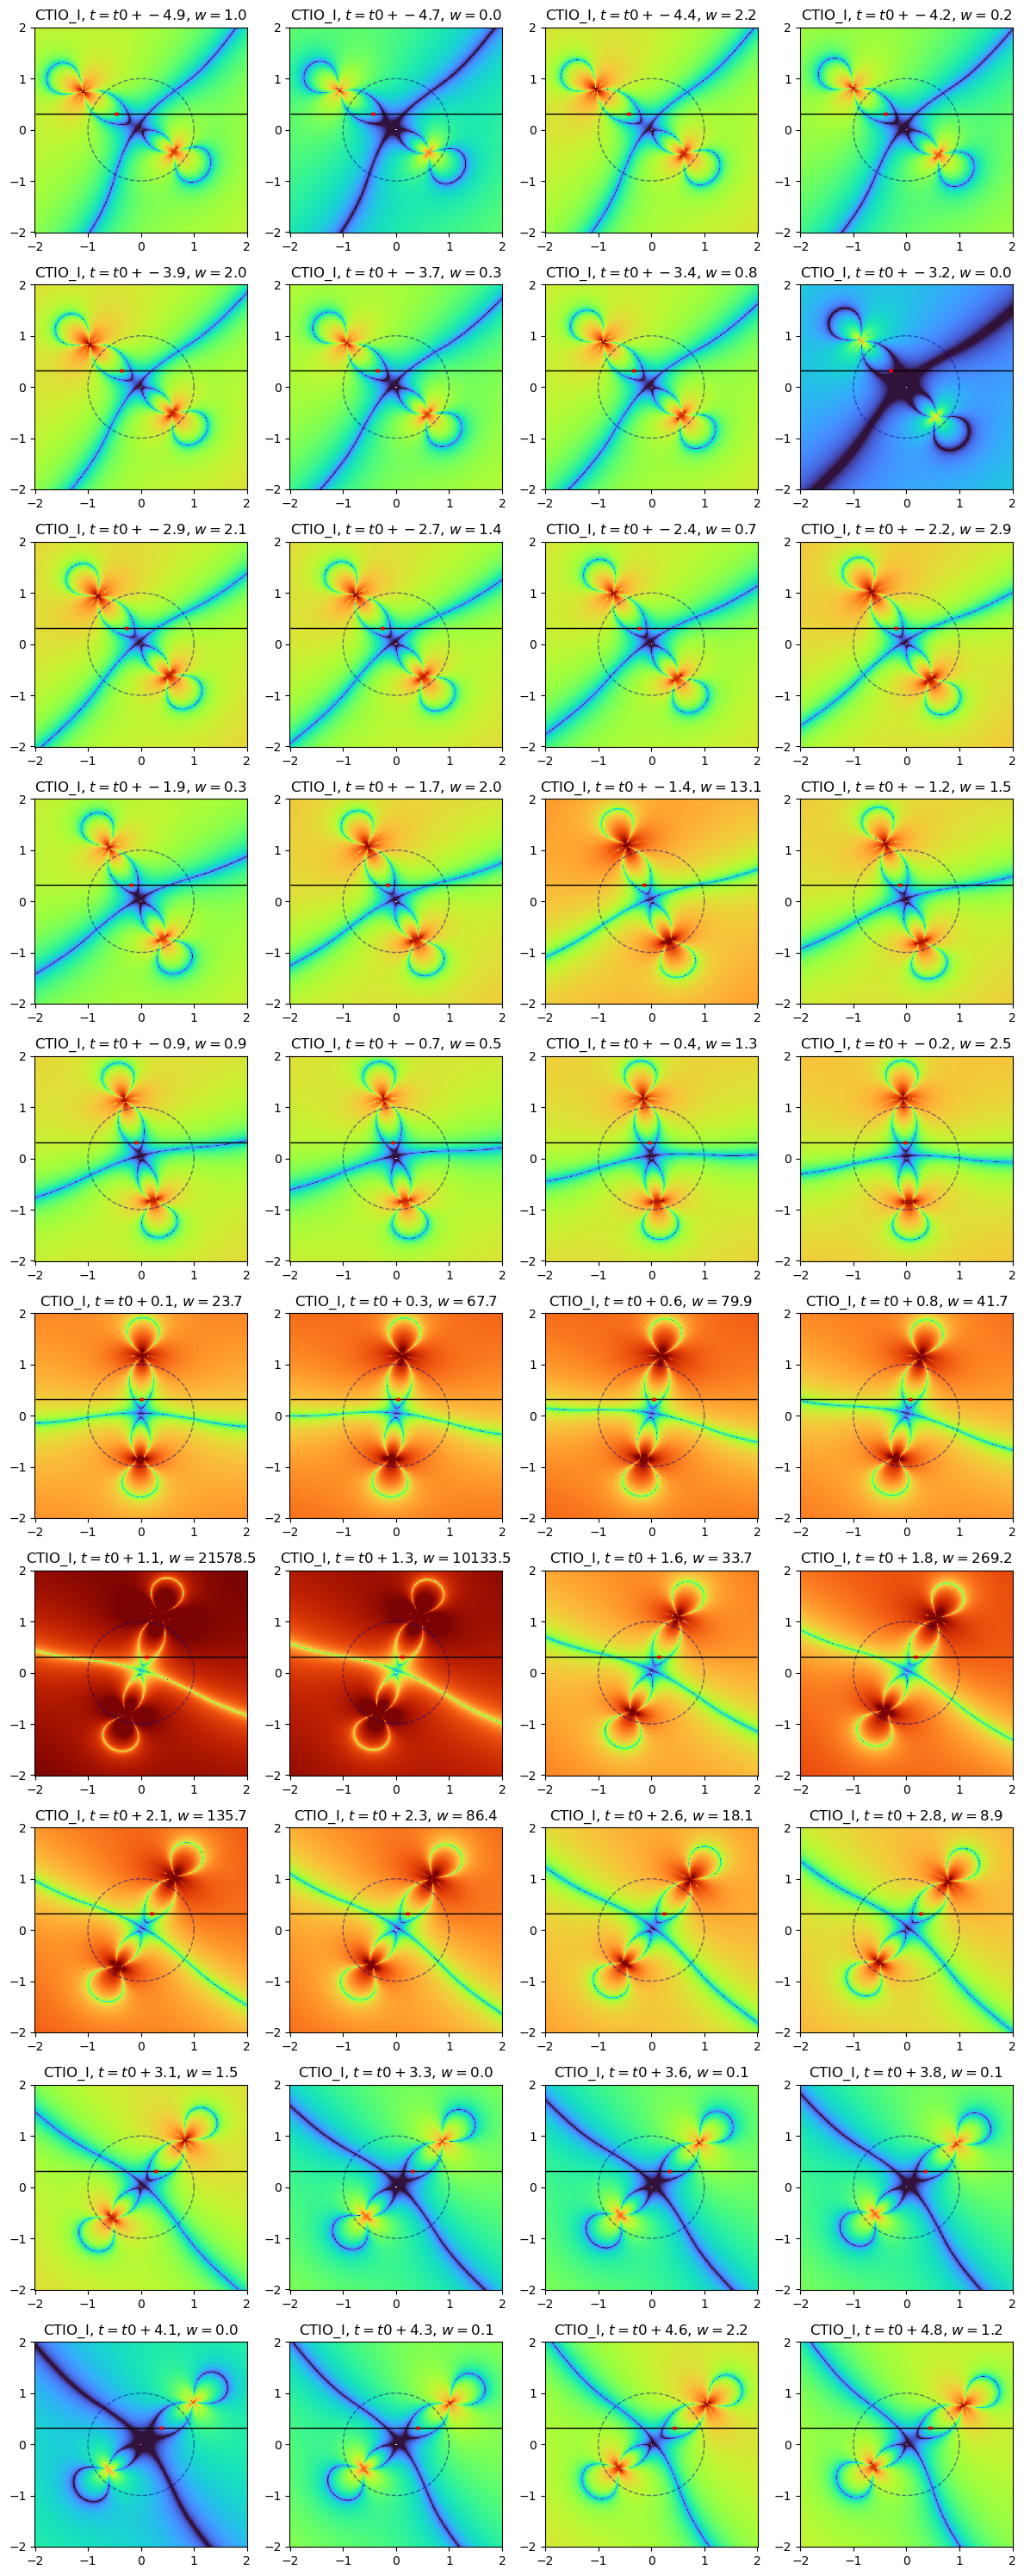

In [3]:
anomaly_map = anomaly_detector.create_map_on_grid(
    meshgrid_limits=((-2.0,2.0),(-2.0,2.0)), 
    resolution=400)

anomaly_plot = PlanetAnomalyPlot(anomaly_map, anomaly_detector)
fig_overview = anomaly_plot.plot_overview(show=True)


/home/jakob/projects/pyLIMA-docs-revisit/my_project/planet_anomaly/planet_anomaly.py:679: UserWarning: Log scale: values of z <= 0 have been masked
  plt.contour(X, Y, Z, levels=14, colors='k', linewidths=0.7, alpha=0.3, norm=norm)


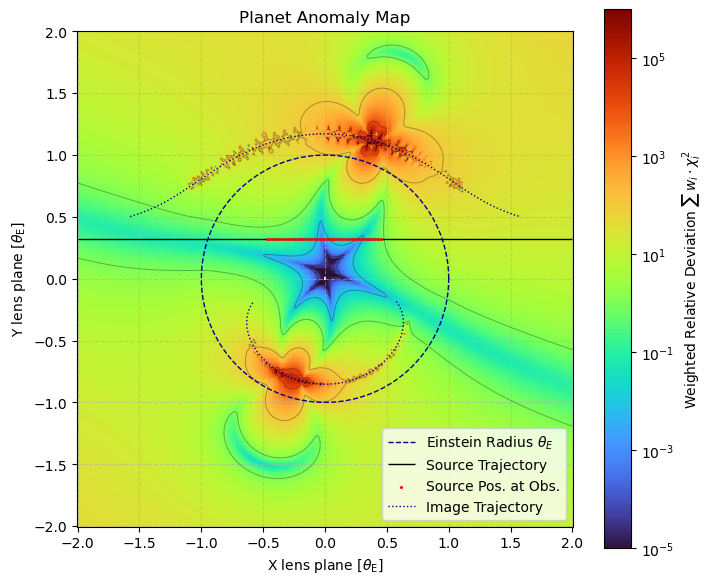

In [4]:
fig_pam = anomaly_plot.plot_map(show=True)
meshgrid, pam = anomaly_map.get_map_on_grid()

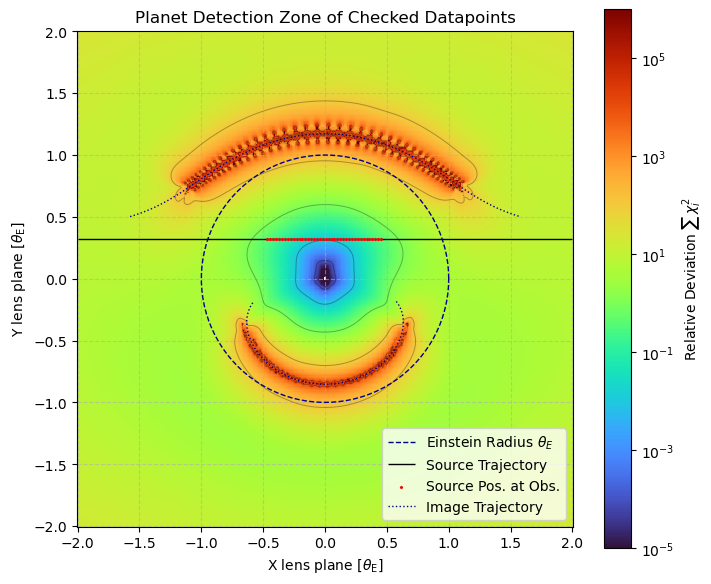

In [5]:
fig_pdz = anomaly_plot.plot_planet_detection_zone(show=True)
meshgrid, pdz = anomaly_map.get_planet_detection_zone_on_grid()

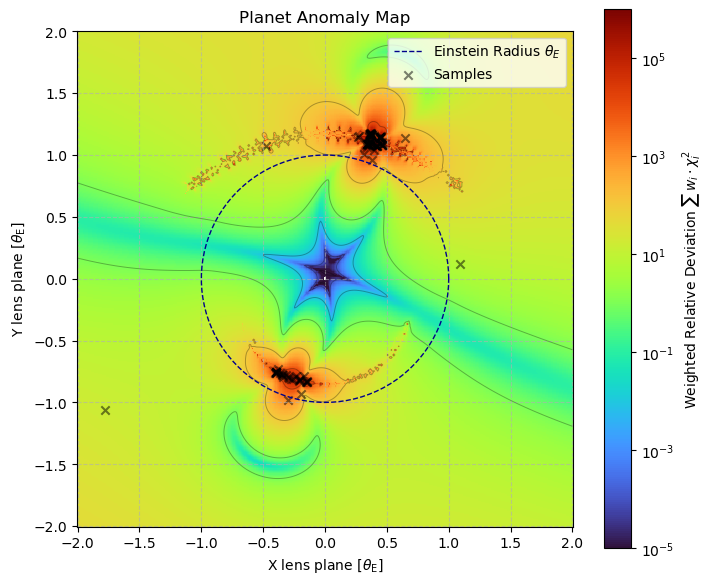

/home/jakob/projects/pyLIMA-docs-revisit/my_project/planet_anomaly/planet_anomaly.py:675: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  contour = plt.pcolormesh(X, Y, Z,


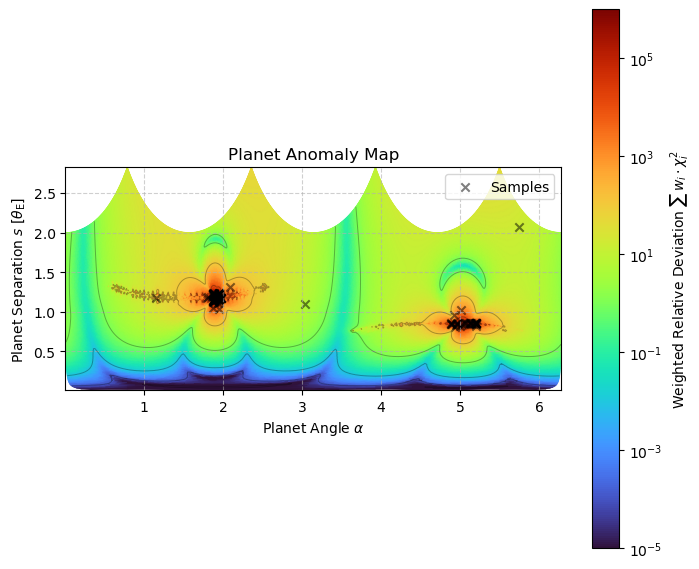

In [6]:
### Create a Sampler Object from Map
anomaly_sampler = PlanetAnomalySampler(anomaly_map)
# Sample and plot in xy coordinates
xy_samples = anomaly_sampler.sample_from_map(n_samples=100)
fig_samples_xy = anomaly_sampler.create_sample_overview_plot(show=True)
# Convert samples to s, alpha coordinates and plot them
s_alpha_samples = anomaly_sampler.convert_xy_to_sa_samples()
fig_samples_salpha = anomaly_sampler.create_sample_overview_plot(show=True, s_alpha_plot=True)

In [7]:
### Run TRF Fits with the sampled Initial Values
import multiprocessing as mp

# use pspl params
t0 = anomaly_detector.t0
u0 = anomaly_detector.u0
te = anomaly_detector.te

# unpack s and alpha samples
s_samples = s_alpha_samples[:,0]
alpha_samples = s_alpha_samples[:,1]

# best fit object
best_fit_params = {'guess' : None,
                   'chi2'  : None}

# create PSBL model
psbl = PSBL_model.PSBLmodel(event_3)
# create fit
fit = TRF_fit.TRFfit(psbl, loss_function='chi2')

for i, (s, alpha) in enumerate(zip(s_samples, alpha_samples)):
    # set initial parameters, fit
    fit.model_parameters_guess = [t0, u0, te, s, 0.001, alpha]
    fit.fit()

    # check chi2
    try:
        if best_fit_params['guess'] == None or fit.fit_results[fit.loss_function] < best_fit_params['chi2']:
            best_fit_params['guess'] = [t0, u0, te, s, 0.001, alpha]
            best_fit_params['chi2'] = fit.fit_results[fit.loss_function]
    except:
        print(f'Fit {i} failed: s={s}, alpha={alpha}\n')

# Run fit again with best parameter
best_fit = TRF_fit.TRFfit(psbl, loss_function='chi2')
best_fit.model_parameters_guess = best_fit_params['guess']
best_fit.fit()


initial_guess  : Initial parameters guess SUCCESS
Using guess:  [2457205.189873185, 0.31873576232245426, 10.614547849984799, 1.2168644884701212, 0.001, 1.890694248030684, 10684.318851087071, 11871.214553425449]
Trust Region Reflective fit SUCCESS
best model:
OrderedDict([('t0', np.float64(2457205.2082059816)),
             ('u0', np.float64(0.3105671643504942)),
             ('tE', np.float64(10.731553878664847)),
             ('separation', np.float64(1.3018280539991962)),
             ('mass_ratio', np.float64(0.0010204715859104545)),
             ('alpha', np.float64(1.9004788852949184)),
             ('fsource_CTIO_I', np.float64(10068.643130190645)),
             ('ftotal_CTIO_I', np.float64(12007.66232067697)),
             ('chi2', np.float64(147.697053642113))])
initial_guess  : Initial parameters guess SUCCESS
Using guess:  [2457205.189873185, 0.31873576232245426, 10.614547849984799, 0.8619967030114958, 0.001, 5.12222855343672, 10684.318851087071, 11871.214553425449]
Trust Reg

Best fit choosen with a chi^2 of 147.69705341208353 and parameters:
OrderedDict([('t0', np.float64(2457205.208205996)),
             ('u0', np.float64(0.31056711340840293)),
             ('tE', np.float64(10.731555184357388)),
             ('separation', np.float64(1.3018280250227077)),
             ('mass_ratio', np.float64(0.0010204716889073253)),
             ('alpha', np.float64(1.9004788969237323)),
             ('fsource_CTIO_I', np.float64(10068.641100296285)),
             ('ftotal_CTIO_I', np.float64(12007.662116483987)),
             ('chi2', np.float64(147.69705341208353))])


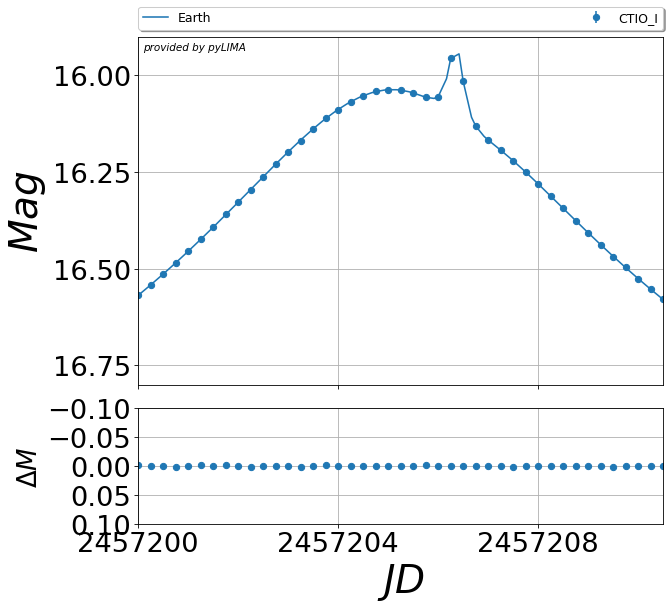

In [8]:
### Give overview over best fit
import pprint
from collections import OrderedDict 

# extract params
best_psbl_params =  OrderedDict(zip(best_fit.priors_parameters.keys(), best_fit.fit_results['best_model']))
best_psbl_params[best_fit.loss_function] = best_fit.fit_results[best_fit.loss_function]

print(f'Best fit choosen with a chi^2 of {best_fit.fit_results['chi2']} and parameters:')
pprint.pprint(best_psbl_params)

# plot
fig, _ = pyLIMA_plots.plot_lightcurves(psbl, best_fit.fit_results['best_model'])
fig.axes[0].set_xlim(2457200.0, 2457210.5)
fig.axes[0].set_ylim(16.8, 15.9)
plt.show()

In [9]:
### Compare best fit params to real values
### Accuracy

# compare absolute values
print(f'Comparison of best of parameters:')
print('')
print(f'  simulation       |   best fit')
print(f't0:     {psbl_sim_params[0]} | {best_psbl_params['t0']}')
print(f'u0:     {psbl_sim_params[1]}      | {best_psbl_params['u0']}')
print(f'tE:     {psbl_sim_params[2]}    | {best_psbl_params['tE']}')
print(f's:      {psbl_sim_params[3]}        | {best_psbl_params['separation']}')
print(f'q:      {psbl_sim_params[4]}      | {best_psbl_params['mass_ratio']}')
print(f'alpha:  {psbl_sim_params[5]}        | {best_psbl_params['alpha']}')
print('')
print(f'chi2 of fit: {best_psbl_params['chi2']}')
print('')

# compare the sigma intervals
print('STD-intervals:')
cov = best_fit.fit_results['covariance_matrix']
unc = np.sqrt(np.diag(cov))
a = np.array(psbl_sim_params)
b = np.array(list(best_psbl_params.values())[:-1])
std = np.abs(a - b) / unc
print(f't0:     {std[0]}')
print(f'u0:     {std[1]}')
print(f'tE:     {std[2]}')
print(f's:      {std[3]}')
print(f'q:      {std[4]}')
print(f'alpha:  {std[5]}')

Comparison of best of parameters:

  simulation       |   best fit
t0:     2457205.21 | 2457205.208205996
u0:     0.309      | 0.31056711340840293
tE:     10.7821    | 10.731555184357388
s:      1.3        | 1.3018280250227077
q:      0.001      | 0.0010204716889073253
alpha:  1.9        | 1.9004788969237323

chi2 of fit: 147.69705341208353

STD-intervals:
t0:     1.3884581628975845
u0:     0.4482671861249187
tE:     0.5210750273142752
s:      0.7078700623065685
q:      1.366365094995907
alpha:  0.5479519221927439
